Sequence data shape: (18731, 20, 21)
Healthy training data: (15631, 20, 21)
Epoch 1/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - loss: 0.0072 - val_loss: 0.0038
Epoch 2/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0040 - val_loss: 0.0038
Epoch 3/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 0.0040 - val_loss: 0.0038
Epoch 4/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0040 - val_loss: 0.0038
Epoch 5/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.0039 - val_loss: 0.0037
Epoch 6/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0039 - val_loss: 0.0037
Epoch 7/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.0039 - val_loss: 0.0037
Epoch 8/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.0039 - val_loss: 0.0036
Epoch 9/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.0038 - val_loss: 0.0036
Epoch 10/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.0038 - val_loss: 0.0036
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step
Fault Thres

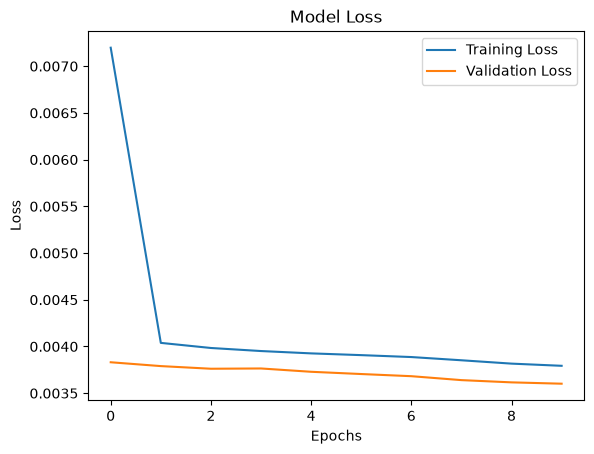

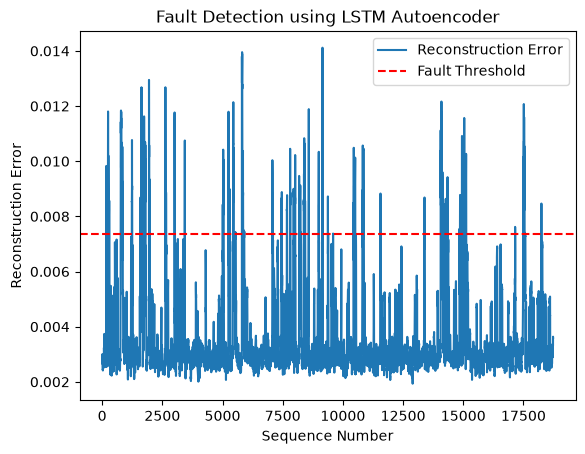

Model saved successfully!


In [2]:

# 1. Import libraries
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 2. Load dataset
data = pd.read_csv("NASA TurboFan Engine.csv")

# 3. Sort data by engine and cycle
data = data.sort_values(["unit", "cycle"])

# 4. Select sensor columns
sensor_columns = [
    "sensor" + str(i) for i in range(1, 22)
]

X = data[sensor_columns].values
y = data["Fault_Label"].values

# 5. Normalize sensor values
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# 6. Create sequences of 20 readings
sequence_length = 20

X_sequences = []
y_sequences = []

# Create sequences separately for each engine
for unit in data["unit"].unique():

    engine_data = data[data["unit"] == unit]

    engine_X = scaler.transform(
        engine_data[sensor_columns].values
    )

    engine_y = engine_data["Fault_Label"].values

    for i in range(len(engine_X) - sequence_length + 1):

        X_sequences.append(
            engine_X[i:i + sequence_length]
        )

        # Label the sequence using its last reading
        y_sequences.append(
            engine_y[i + sequence_length - 1]
        )

X_sequences = np.array(X_sequences)
y_sequences = np.array(y_sequences)

print("Sequence data shape:", X_sequences.shape)

# 7. Split healthy and faulty data
X_train = X_sequences[y_sequences == 0]

print("Healthy training data:", X_train.shape)

# 8. Build LSTM Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(20, 21)),

    tf.keras.layers.LSTM(64),

    tf.keras.layers.RepeatVector(20),

    tf.keras.layers.LSTM(64, return_sequences=True),

    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(21)
    )
])

# 9. Compile model
model.compile(
    optimizer="adam",
    loss="mse"
)

# 10. Train the model using healthy data
history = model.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

# 11. Reconstruct all sequences
reconstructed = model.predict(X_sequences)

# 12. Calculate reconstruction error
errors = np.mean(
    np.square(X_sequences - reconstructed),
    axis=(1, 2)
)

# 13. Set fault threshold
threshold = np.percentile(errors, 95)

print("Fault Threshold:", threshold)

# 14. Predict faults
predictions = (errors > threshold).astype(int)

# 15. Calculate accuracy
accuracy = np.mean(predictions == y_sequences)

print("Fault Detection Accuracy:", accuracy * 100, "%")

# 16. Plot training loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 17. Plot reconstruction errors
plt.plot(errors, label="Reconstruction Error")
plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Fault Threshold"
)
plt.title("Fault Detection using LSTM Autoencoder")
plt.xlabel("Sequence Number")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()

# 18. Save model
model.save("nasa_turbofan_autoencoder.keras")

print("Model saved successfully!")


## Practical 3D – Fault Detection in NASA Turbofan Engine Dataset using LSTM Autoencoder

Problem statement: Detect faults in sensor data from machinery (NASA Turbofan Engine Dataset) using an Autoencoder. Train an LSTM-based autoencoder on healthy engine sensor readings and detect faults using reconstruction error.

### 1. Understand the practical

Imagine an aircraft engine has 21 sensors measuring different parameters, such as temperature, pressure, and speed.

- Healthy engine → sensors show normal patterns.
- Faulty engine → sensor readings behave unusually.
- The Autoencoder learns normal sensor patterns and detects unusual readings using reconstruction error.

[Data-Driven Deep Learning-Based Attention Mechanism for Remaining Useful Life Prediction: Case Study Application to Turbofan Engine Analysis](https://images.openai.com/static-rsc-4/GpcHywTB5WSHIgoR4hB19o1Y9sr4eZrvsFPyKof46ThORv-ItwFwyF2IZuy1U7kELA5B4C-zyuvNraeeT4fNlVHkxwqYbmrQuM3xebZyt5Ilah4EtAlxE8zg4YTcw1paa-EwBv_9Xn8vJXaw-mlmzk3plVhLsmaH3QYZU-NUp-c?purpose=inline)

[mdpi.com](https://www.mdpi.com/2079-9292/10/20/2453?utm_source=chatgpt.com)

### 2. Understand the working

NASA Turbofan Dataset

21 sensor readings

Preprocessing

Sort by engine, scale sensor values

Create Sequences

20 consecutive sensor readings

LSTM Autoencoder

Encoder → Decoder

Reconstruction Error

Error above threshold = Fault

### 3. Explanation of your code

Step 1 – Import libraries

```
import pandas as pdimport numpy as npimport tensorflow as tfimport matplotlib.pyplot as pltfrom sklearn.preprocessing import MinMaxScaler
```

- Pandas: loads the dataset.
- NumPy: mathematical calculations.
- TensorFlow: builds the LSTM Autoencoder.
- Matplotlib: plots graphs.
- MinMaxScaler: normalizes sensor values.

Step 2 – Load and sort dataset

```
data = pd.read_csv("NASA TurboFan Engine.csv")data = data.sort_values(["unit", "cycle"])
```

- `unit` identifies the engine.
- `cycle` identifies the operating cycle or reading number.
- Sorting ensures readings are in chronological order for each engine.

Step 3 – Select sensor columns

```
sensor_columns = [    "sensor" + str(i) for i in range(1, 22)]X = data[sensor_columns].valuesy = data["Fault_Label"].values
```

There are 21 sensor features.

- `X` contains sensor readings.
- `y` contains fault labels.

Step 4 – Normalize sensor values

```
scaler = MinMaxScaler()X = scaler.fit_transform(X)
```

Converts sensor values into a range between 0 and 1.

Why? Different sensors may have different numerical ranges. Normalization helps the model learn effectively.

Step 5 – Create sequences

```
sequence_length = 20
```

This means the model looks at 20 consecutive readings together.

For example:

One sequence

1

2

3

4

5

6

7

8

9

10

11

12

13

14

15

16

17

18

19

20

20 consecutive readings form one sequence.

The loop:

```
for unit in data["unit"].unique():    engine_data = data[data["unit"] == unit]
```

Processes each engine separately.

Why separately? We should not combine the last readings of one engine with the first readings of another engine.

Then:

```
X_sequences.append(engine_X[i:i + sequence_length])
```

Selects 20 consecutive sensor readings.

```
y_sequences.append(engine_y[i + sequence_length - 1])
```

Uses the label of the last reading as the sequence label.

Step 6 – Select healthy sequences

```
X_train = X_sequences[y_sequences == 0]
```

Selects only healthy sequences for training.

Why? The model must learn normal engine behaviour so that it can identify unusual behaviour later.

Step 7 – Build LSTM Autoencoder

This is the most important part.

```
model = tf.keras.Sequential([    tf.keras.layers.Input(shape=(20, 21)),    tf.keras.layers.LSTM(64),    tf.keras.layers.RepeatVector(20),    tf.keras.layers.LSTM(64, return_sequences=True),    tf.keras.layers.TimeDistributed(        tf.keras.layers.Dense(21)    )])
```

| Layer                             | Meaning                                     |
| --------------------------------- | ------------------------------------------- |
| `Input(20,21)`                    | 20 readings with 21 sensors each            |
| `LSTM(64)`                        | Learns and compresses sequential patterns   |
| `RepeatVector(20)`                | Repeats compressed information 20 times     |
| `LSTM(64, return_sequences=True)` | Reconstructs the sequence                   |
| `TimeDistributed(Dense(21))`      | Produces 21 sensor values at each time step |

Remember: Encoder compresses the information; decoder reconstructs it.

Step 8 – Compile model

```
model.compile(    optimizer="adam",    loss="mse")
```

- Adam: optimizer.
- MSE: measures reconstruction error.

Step 9 – Train model

```
history = model.fit(    X_train,    X_train,    epochs=10,    batch_size=32,    validation_split=0.1)
```

Why is `X_train` written twice?

Because the model learns to reconstruct its own input.

- Epochs = 10: trains 10 times.
- Batch size = 32: processes 32 sequences at once.
- Validation split = 0.1: uses 10% of training data for validation.

Step 10 – Calculate reconstruction error

```
reconstructed = model.predict(X_sequences)errors = np.mean(    np.square(X_sequences - reconstructed),    axis=(1, 2))
```

Compares original sensor sequences with reconstructed sequences.

- Low error → likely healthy.
- High error → possibly faulty.

Step 11 – Set threshold

```
threshold = np.percentile(errors, 95)
```

Calculates the 95th percentile of reconstruction errors.

Step 12 – Predict faults

```
predictions = (errors > threshold).astype(int)
```

- `0` = healthy.
- `1` = faulty.

Step 13 – Calculate accuracy

```
accuracy = np.mean(predictions == y_sequences)print("Fault Detection Accuracy:", accuracy * 100, "%")
```

Compares predicted labels with actual labels.

Step 14 – Plot and save model

The first graph displays training and validation loss.

The second graph displays reconstruction errors and the fault threshold.

```
model.save("nasa_turbofan_autoencoder.keras")
```

Saves the trained model.

### 4. Important viva questions

Q1. What is NASA Turbofan Engine Dataset?

It is a dataset containing engine operating conditions and sensor readings used for studying engine degradation and fault prediction.

Q2. Why do we use LSTM?

Because sensor readings are sequential. LSTM learns patterns across time.

Q3. What is a sequence?

A group of consecutive sensor readings. Here, each sequence contains 20 readings.

Q4. Why do we train only on healthy data?

So the model learns normal engine behaviour and identifies deviations from it.

Q5. What is reconstruction error?

It is the difference between original sensor readings and reconstructed sensor readings.

Q6. What is the purpose of the threshold?

It decides whether the reconstruction error is high enough to classify a sequence as faulty.

Q7. What does `unit` represent?

It identifies an individual engine.

Q8. What does `cycle` represent?

It represents the engine's operating cycle or time-step reading.

Q9. What is `RepeatVector(20)`?

It repeats the compressed representation 20 times for the decoder.

Q10. What is the difference between Practical 3C and 3D?

| Practical 3C            | Practical 3D           |
| ----------------------- | ---------------------- |
| Smart Grid dataset      | NASA Turbofan dataset  |
| Electricity consumption | Engine sensor readings |
| 5 features              | 21 sensors             |
| Window size 24          | Sequence length 20     |
| Energy anomalies        | Machinery faults       |

### 5. What to tell the examiner

"I implemented machinery fault detection using an LSTM Autoencoder on the NASA Turbofan Engine dataset. First, I loaded the sensor data and sorted it by engine unit and cycle. Then I normalized the 21 sensor readings and created sequences of 20 readings. I selected only healthy sequences for training. Next, I built an LSTM Autoencoder to learn normal engine behaviour. Finally, I calculated reconstruction errors, applied a threshold, and classified high-error sequences as faulty."

### 6. Quick revision

| Parameter       | Value             |
| --------------- | ----------------- |
| Dataset         | NASA Turbofan     |
| Model           | LSTM Autoencoder  |
| Sensors         | 21                |
| Sequence length | 20                |
| Training data   | Healthy sequences |
| LSTM units      | 64                |
| Optimizer       | Adam              |
| Loss            | MSE               |
| Epochs          | 10                |
| Batch size      | 32                |
| Threshold       | 95th percentile   |

Important correction in your code

Your code calculates the threshold using `errors` from all sequences, including faulty ones:

```
threshold = np.percentile(errors, 95)
```

A better approach is to calculate the threshold using reconstruction errors from a separate healthy validation set. Also, fit `MinMaxScaler` on training data only to avoid data leakage.

One more thing: the NASA C-MAPSS dataset commonly contains run-to-failure engine data rather than a direct `Fault_Label` column. Your CSV must actually contain the `Fault_Label` column with `0 = healthy` and `1 = faulty` for this code to run as written.